# Document Detection with YOLOv8 Instance Segmentation Model with 200 Epochs

In [ ]:
!nvidia-smi

Wed Oct 22 07:03:14 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLOv8

In [ ]:
# Pip install method (recommended)

!pip install ultralytics==8.2.103 -q

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 38.6/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
!rm -rf /content/datasets

In [ ]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow --quiet

import roboflow

!pip install roboflow

from roboflow import Roboflow

# Load Dataset

/content/datasets
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 29.0 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to document_detection-9 in yolov8:: 100%|██████████| 1341/1341 [00:00<00:00, 6571.53it/s]


In [ ]:
import yaml

with open(f"{dataset.location}/data.yaml", 'r') as f:
    dataset_yaml = yaml.safe_load(f)
dataset_yaml["train"] = "../train/images"
dataset_yaml["val"] = "../valid/images"
dataset_yaml["test"] = "../test/images"
with open(f"{dataset.location}/data.yaml", 'w') as f:
    yaml.dump(dataset_yaml, f)

## Custom Training

In [ ]:
%cd {HOME}

!yolo task=segment mode=train model=yolov8s-seg.pt data={dataset.location}/data.yaml epochs=200 imgsz=640 save_txt=true save_conf=true iou=0.75

/content
100% 22.8M/22.8M [00:00<00:00, 87.2MB/s]
New https://pypi.org/project/ultralytics/8.3.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=yolov8s-seg.pt, data=/content/datasets/document_detection-9/data.yaml, epochs=200, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.75, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agno

In [ ]:
!ls {HOME}/runs/segment/train/

args.yaml					   MaskR_curve.png
BoxF1_curve.png					   results.csv
BoxP_curve.png					   results.png
BoxPR_curve.png					   train_batch0.jpg
BoxR_curve.png					   train_batch1.jpg
confusion_matrix_normalized.png			   train_batch2.jpg
confusion_matrix.png				   train_batch6650.jpg
events.out.tfevents.1761116672.b91e9559b933.605.0  train_batch6651.jpg
labels						   train_batch6652.jpg
labels_correlogram.jpg				   val_batch0_labels.jpg
labels.jpg					   val_batch0_pred.jpg
MaskF1_curve.png				   val_batch1_labels.jpg
MaskP_curve.png					   val_batch1_pred.jpg
MaskPR_curve.png				   weights


/content


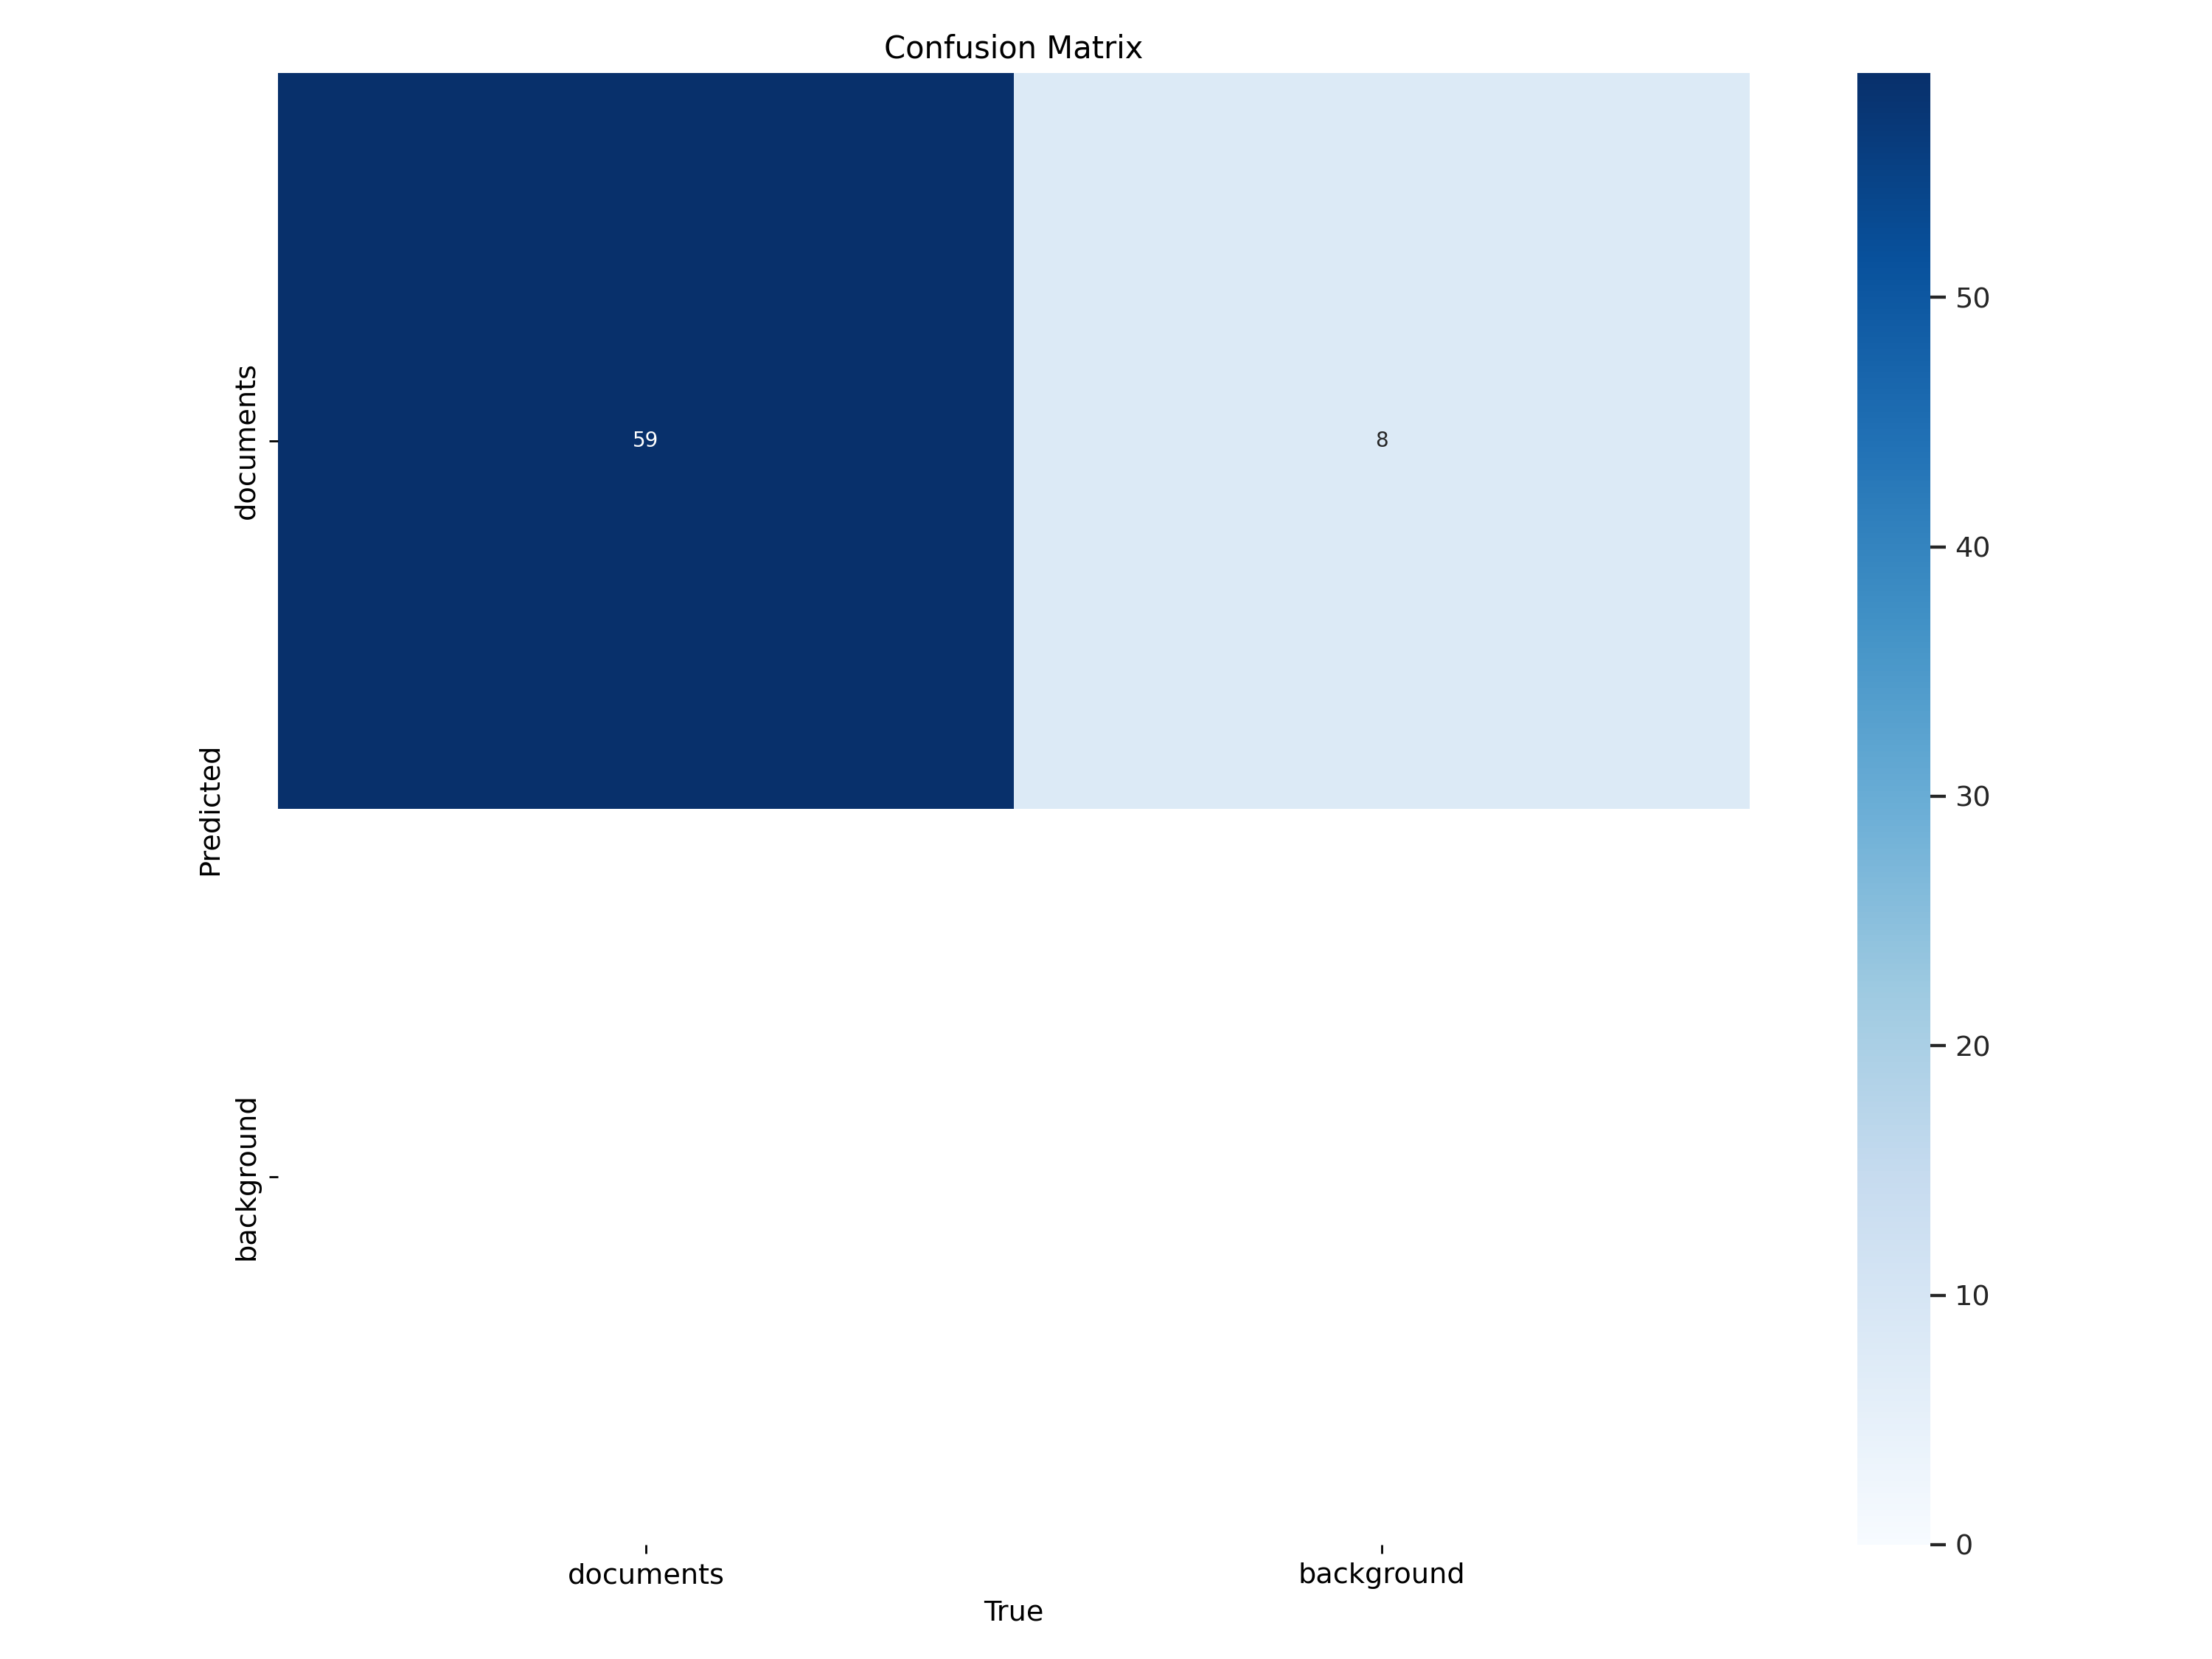

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train/confusion_matrix.png', width=600)

/content


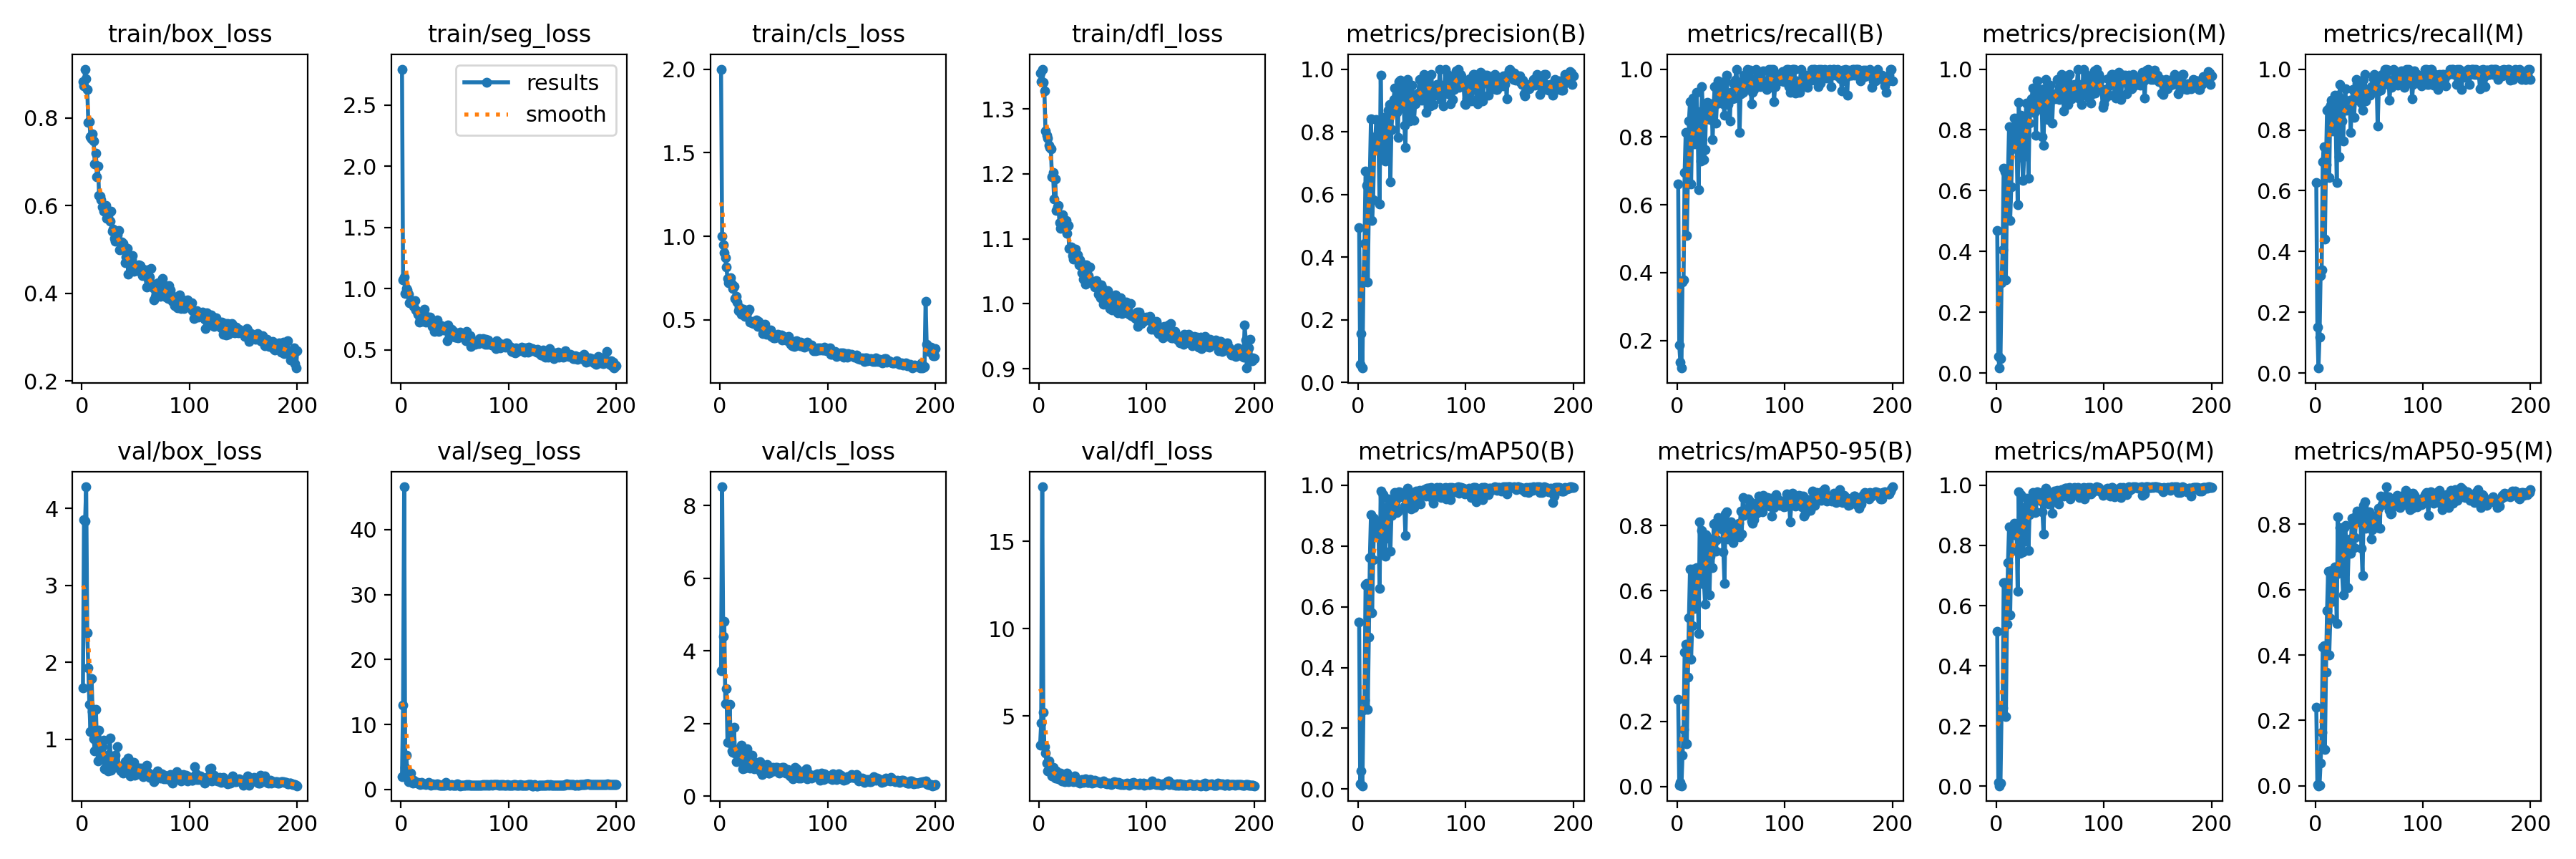

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train/results.png', width=600)

/content


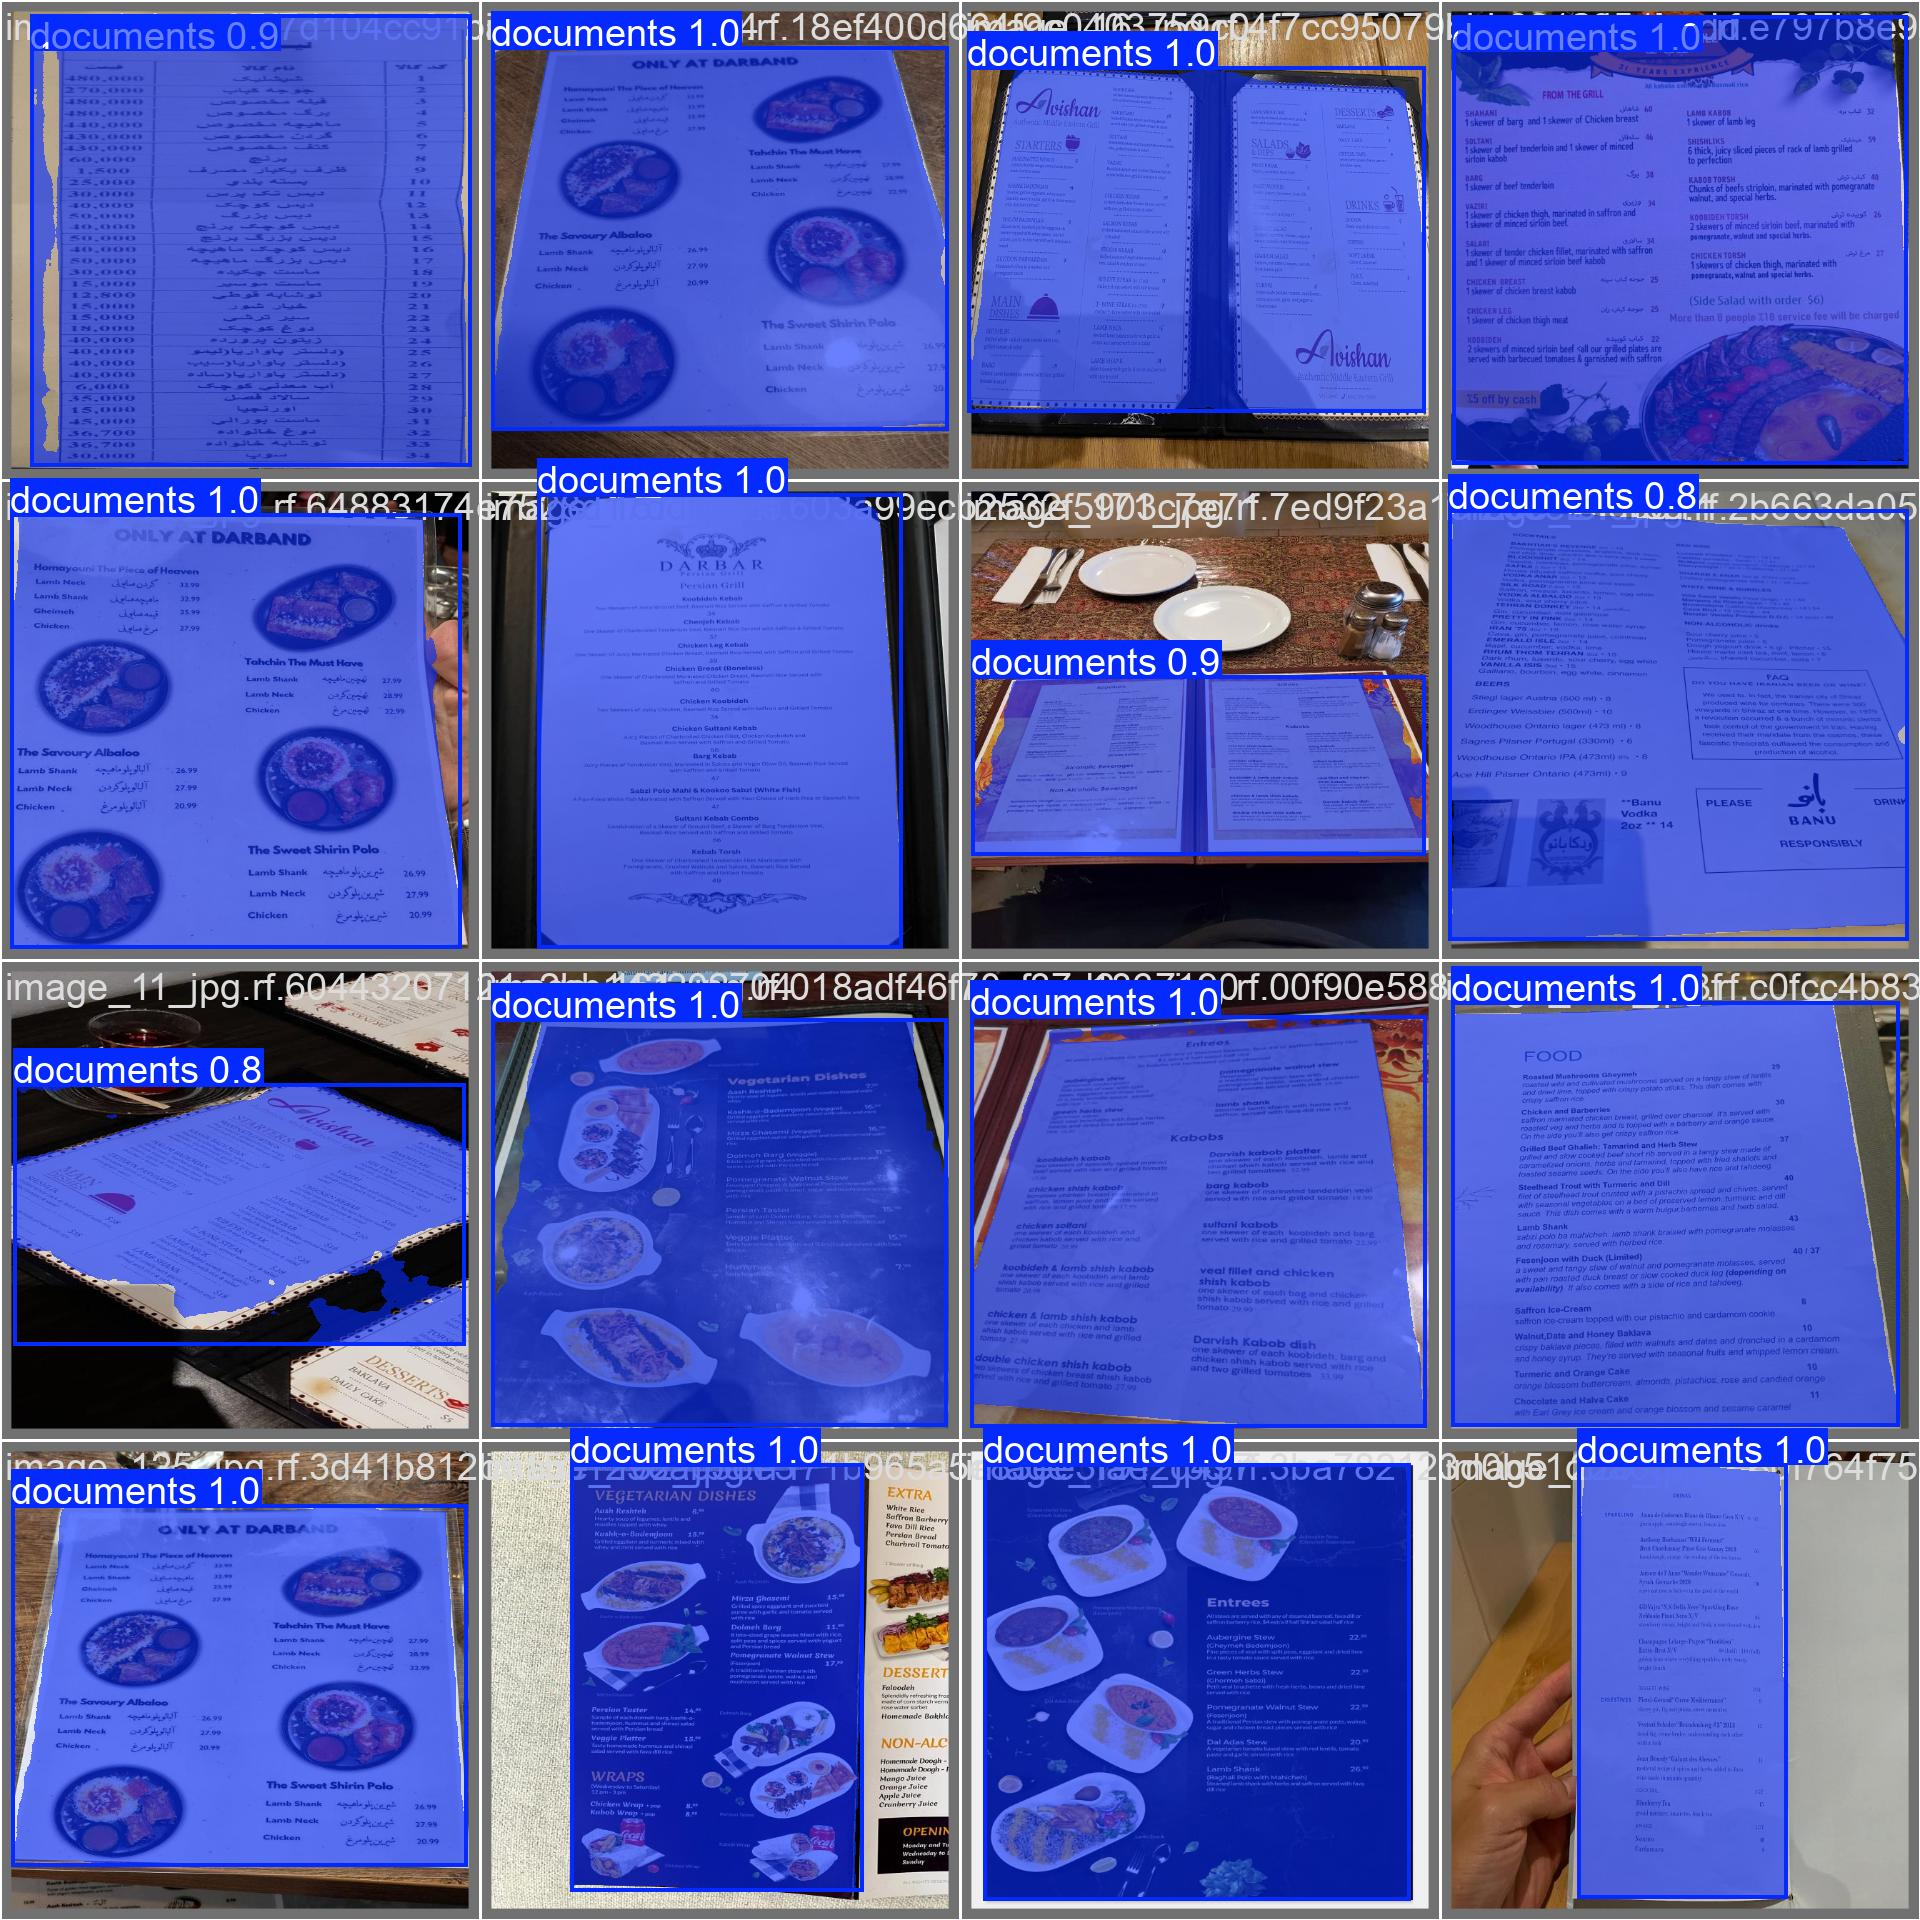

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train/val_batch0_pred.jpg', width=600)

## Validate Custom Model

In [ ]:
%cd {HOME}

!yolo task=segment mode=val model={HOME}/runs/segment/train/weights/best.pt data={dataset.location}/data.yaml save_txt=true save_conf=true iou=0.75

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8s-seg summary (fused): 195 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs
100% 755k/755k [00:00<00:00, 163MB/s]
val: Scanning /content/datasets/document_detection-9/valid/labels... 59 images, 0 backgrounds, 0 corrupt: 100% 59/59 [00:00<00:00, 968.05it/s]
val: New cache created: /content/datasets/document_detection-9/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% 4/4 [00:08<00:00,  2.06s/it]
                   all         59         59      0.978      0.966      0.993      0.919      0.978      0.966      0.993      0.906
Speed: 7.7ms preprocess, 16.4ms inference, 0.1ms loss, 7.2ms postprocess per image
Results saved to runs/segment/val2
💡 Learn more at https://docs.ultralytics.com/modes/val


## Inference with Custom Model

In [ ]:
%cd {HOME}
!yolo task=segment mode=predict model={HOME}/runs/segment/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=true save_txt=true save_conf=true iou=0.75

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8s-seg summary (fused): 195 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs

image 1/58 /content/datasets/document_detection-9/test/images/image16_jpg.rf.31a11fbf32592dad7678730b1b9e554d.jpg: 640x640 1 documents, 20.8ms
image 2/58 /content/datasets/document_detection-9/test/images/image17_jpg.rf.11e07ca97336de3e7c4bd4abbcd01c1a.jpg: 640x640 1 documents, 20.9ms
image 3/58 /content/datasets/document_detection-9/test/images/image_104_jpg.rf.8889b0ec6fd69207ddff1772bfb291a8.jpg: 640x640 (no detections), 20.8ms
image 4/58 /content/datasets/document_detection-9/test/images/image_108_jpg.rf.6dda7c5f97b29ac51a4fd3a79bb6d44e.jpg: 640x640 1 documents, 20.8ms
image 5/58 /content/datasets/document_detection-9/test/images/image_118_jpg.rf.c68c9401810af07ac5431070c81b69f0.jpg: 640x640 2 documentss, 20.8ms
image 6/58 /content/datasets/document_detection-9/test/images/image_120_jpg.rf.1cbd16e5

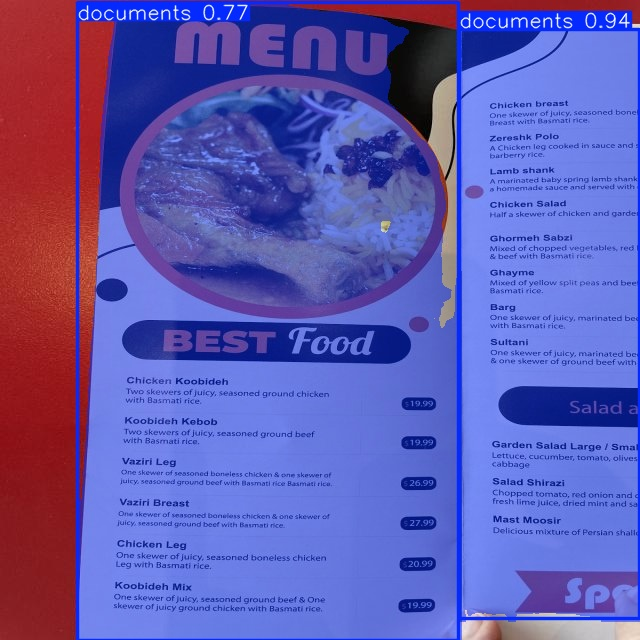

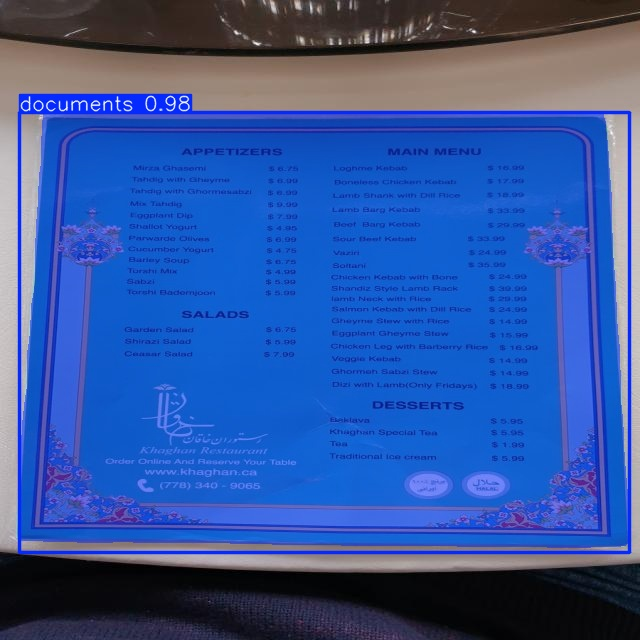

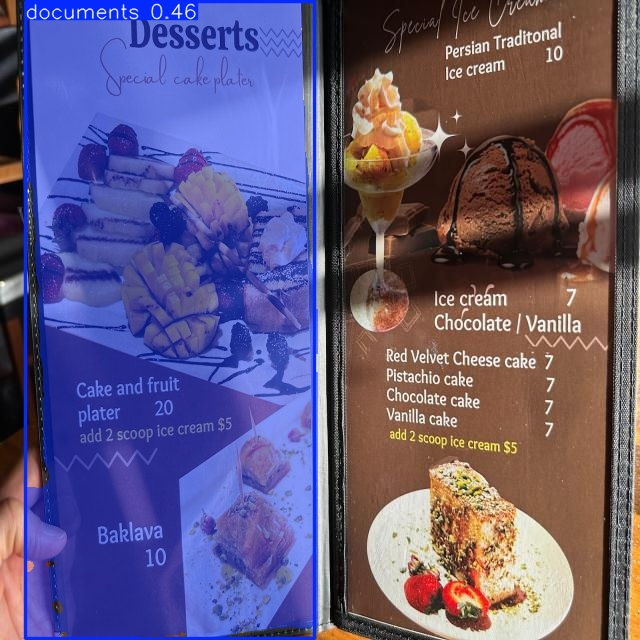

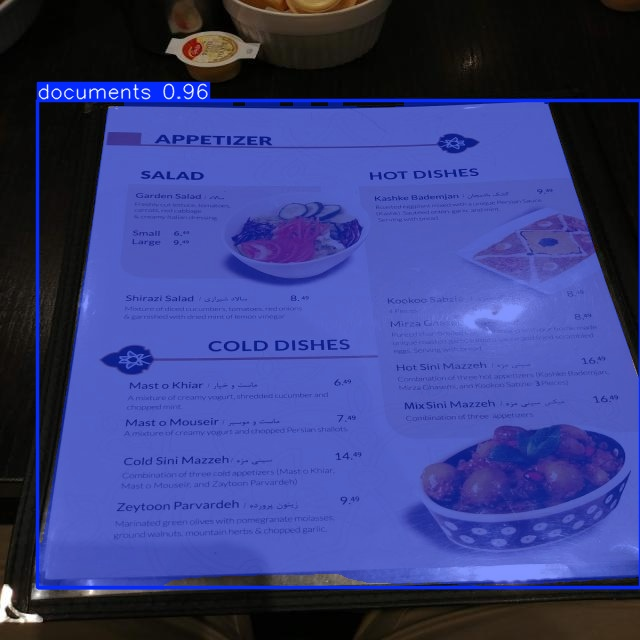

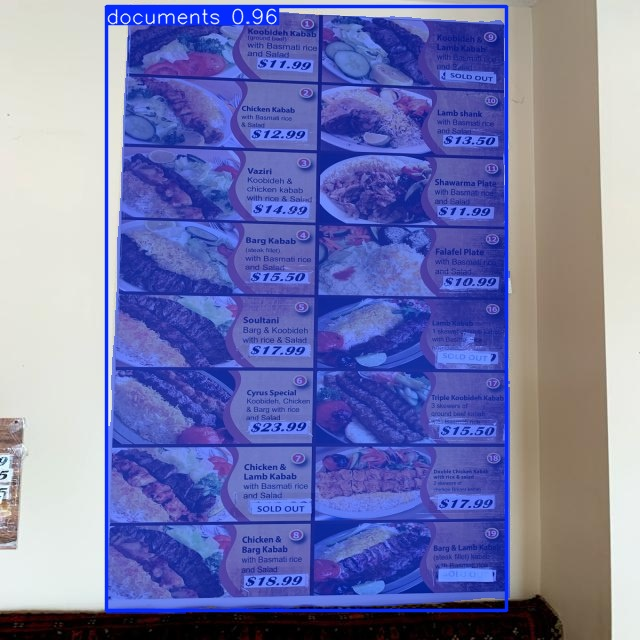

In [ ]:
import glob
from IPython.display import Image, display

for image_path in glob.glob(f'{HOME}/runs/segment/predict/*.jpg')[:5]:
      display(Image(filename=image_path, height=600))
      print("\n")

In [ ]:
!zip -r runs.zip runs

  adding: runs/ (stored 0%)
  adding: runs/segment/ (stored 0%)
  adding: runs/segment/predict/ (stored 0%)
  adding: runs/segment/predict/image_352_jpg.rf.007bd660b852d13912fc538fe5e72305.jpg (deflated 3%)
  adding: runs/segment/predict/image_52_jpg.rf.d5b43117c11589339baa4f703cd1dfee.jpg (deflated 3%)
  adding: runs/segment/predict/image_227_jpg.rf.de0b67e61aa4b28ffdcff5df8733a37d.jpg (deflated 3%)
  adding: runs/segment/predict/image_296_jpg.rf.ef97bd98f42ee717a6a606dd9839019f.jpg (deflated 5%)
  adding: runs/segment/predict/image_86_jpg.rf.0b0e00e4462c0dc775728987a409ece1.jpg (deflated 3%)
  adding: runs/segment/predict/image_141_jpg.rf.91cc272bcd5813d1ac942e52065f617c.jpg (deflated 4%)
  adding: runs/segment/predict/image_66_jpg.rf.a3c326f7a28a6322cbe353cef5e704d2.jpg (deflated 3%)
  adding: runs/segment/predict/image_314_jpg.rf.7071423367f14c68845c42ce522ed1b1.jpg (deflated 2%)
  adding: runs/segment/predict/image_139_jpg.rf.7d02ae59a80a09c5c227bcd46c2de4c6.jpg (deflated 3%)
  ad